Import Libraries

In [8]:

# Part 1: Import Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import (
    train_test_split, StratifiedKFold,
    RandomizedSearchCV, cross_validate
)

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import BernoulliNB
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay
)


Load the Datasets

In [9]:

# Part 2: Load the Datasets
train = pd.read_excel("Training Dataset.xlsx")
test = pd.read_excel("Testing Dateset.xlsx")

print("Training dataset:", train.shape)
print("Testing dataset:", test.shape)

print("\nFirst five rows:")
print(train.head())

print("\nDataset information:")
train.info()


Training dataset: (177086, 23)
Testing dataset: (44272, 23)

First five rows:
   ID Start Date   End Date  Estimated Win Rate     Price Customer Segment 1  \
0   1 2021-03-16 2021-04-20                0.75   3270.83                  I   
1   2 2021-03-18 2021-08-16                0.50   3772.74                  I   
2   3 2021-04-01 2021-09-03                0.10   2230.27                  I   
3   4 2021-04-08 2021-07-01                0.50   5000.00                  I   
4   5 2021-03-17 2023-08-24                0.20  51506.23                  I   

  Customer Segment 2 Customer Segment 3 Customer Segment 4 Customer Segment 5  \
0                  A                 AA                CCC                 AB   
1                  A                 AA                CCC                 AB   
2                  A                 AA                CCC                 AB   
3                  A                 AA                CCC                 AB   
4                  A                

Data Understanding

In [10]:


print("Statistical Summary:")
print(train.describe(include="all").to_string())

print("\nColumn Names:")
print(train.columns.tolist())

print("\nTarget Distribution:")
print(train["Result"].value_counts())

print("\nTarget Percentages:")
print(train["Result"].value_counts(normalize=True) * 100)


Statistical Summary:
                   ID                     Start Date                       End Date  Estimated Win Rate         Price Customer Segment 1 Customer Segment 2 Customer Segment 3 Customer Segment 4 Customer Segment 5   Unit Number Activity 1 Activity 2 Country    City Product Competitor Marketing Source Division    Manager  Techincal Manager Customer ID         Result
count   177086.000000                         177086                         177086       166527.000000  1.770860e+05             177086             177086             177086             177086             177086  1.770860e+05     177086     177086  177086  177030  177044     175980           177035   177085   153061.0            10354.0      177086  177086.000000
unique            NaN                            NaN                            NaN                 NaN           NaN                  7                  5                  7                  4                  2           NaN          2        

Check Data Quality

In [11]:

# Check Data Quality

print("Missing Values in Training Data:")
print(train.isnull().sum())

print("\nMissing Values in Testing Data:")
print(test.isnull().sum())

print("\nDuplicate Rows:")
print("Training:", train.duplicated().sum())
print("Testing:", test.duplicated().sum())

print("\nData Types:")
print(train.dtypes)

quality = pd.DataFrame({
    "Column": train.columns,
    "Missing": train.isnull().sum().values,
    "Missing_Percent": (
        train.isnull().mean().values * 100
    ).round(2),
    "Unique_Values": train.nunique().values
})

print("\nData Quality Summary:")
print(quality)

quality.to_csv("data_quality.csv", index=False)


Missing Values in Training Data:
ID                         0
Start Date                 0
End Date                   0
Estimated Win Rate     10559
Price                      0
Customer Segment 1         0
Customer Segment 2         0
Customer Segment 3         0
Customer Segment 4         0
Customer Segment 5         0
Unit Number                0
Activity 1                 0
Activity 2                 0
Country                    0
City                      56
Product                   42
Competitor              1106
Marketing Source          51
Division                   1
Manager                24025
Techincal Manager     166732
Customer ID                0
Result                     0
dtype: int64

Missing Values in Testing Data:
ID                        0
Start Date                0
End Date                  0
Estimated Win Rate        0
Price                     0
Customer Segment 1        0
Customer Segment 2        0
Customer Segment 3        0
Customer Segment 4        0
Cu

Data Cleaning

In [12]:

# Part 5: Data Cleaning

train_clean = train.copy()
test_clean = test.copy()

# Remove duplicate records
train_clean = train_clean.drop_duplicates()

# Remove rows with missing target values
train_clean = train_clean.dropna(subset=["Result"])

# Clean text values
for data in [train_clean, test_clean]:

    text_columns = data.select_dtypes(
        include=["object"]
    ).columns

    for col in text_columns:
        data[col] = data[col].apply(
            lambda x: x.strip() if isinstance(x, str) else x
        )
        data[col] = data[col].replace("", np.nan)

# Convert date columns
for data in [train_clean, test_clean]:

    for col in ["Start Date", "End Date"]:

        if col in data.columns:
            data[col] = pd.to_datetime(
                data[col], errors="coerce"
            )

            data.loc[
                data[col].dt.year <= 1900, col
            ] = pd.NaT

# Check invalid numeric values
for data in [train_clean, test_clean]:

    for col in ["Price", "Unit Number"]:

        if col in data.columns:
            data.loc[data[col] < 0, col] = np.nan

# Check outliers using IQR
for col in ["Price", "Unit Number"]:

    if col in train_clean.columns:

        Q1 = train_clean[col].quantile(0.25)
        Q3 = train_clean[col].quantile(0.75)
        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        outliers = (
            (train_clean[col] < lower) |
            (train_clean[col] > upper)
        ).sum()

        print(col, "Outliers:", outliers)

# Keep valid outliers because large orders may be real.

print("\nRows Before Cleaning:", len(train))
print("Rows After Cleaning:", len(train_clean))


Price Outliers: 28824
Unit Number Outliers: 4062

Rows Before Cleaning: 177086
Rows After Cleaning: 177086


Exploratory Data Analysis

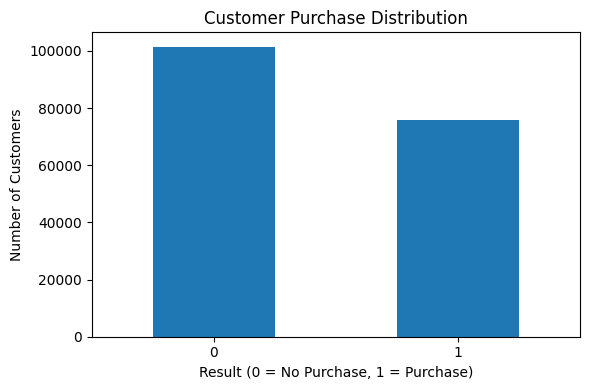

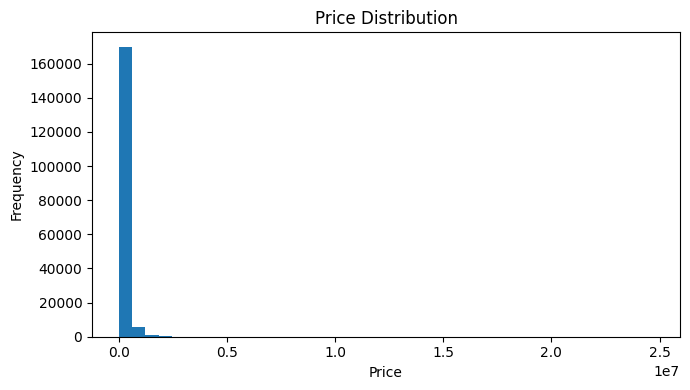

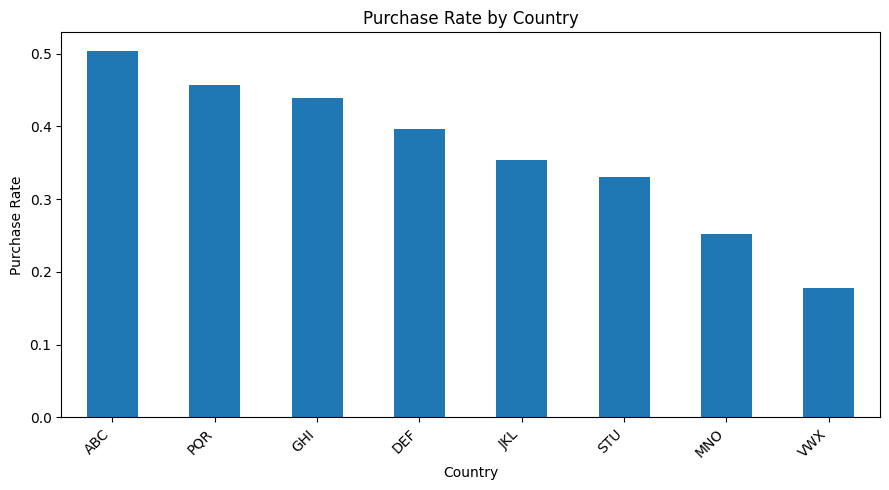

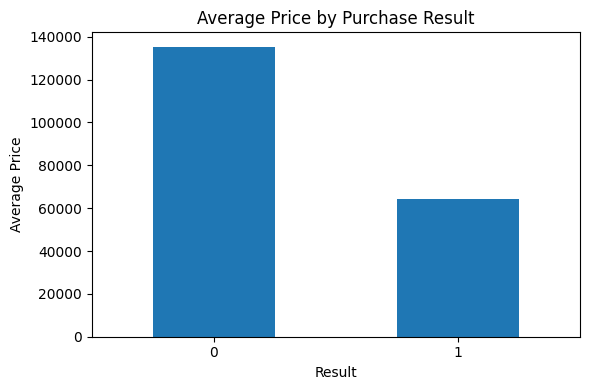

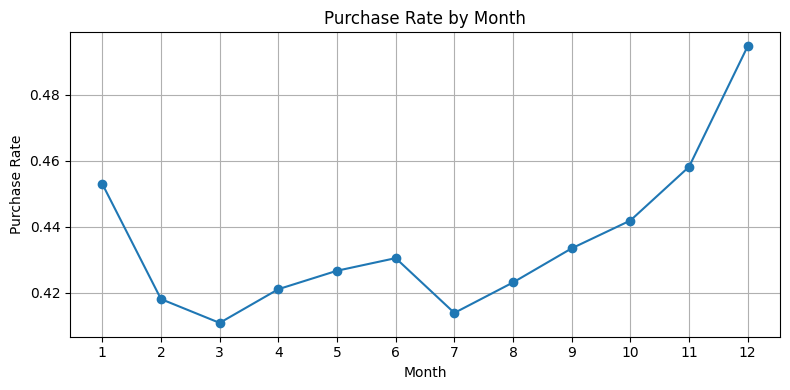

In [13]:

# Part 6: Exploratory Data Analysis

# Chart 1: Purchase Distribution

train_clean["Result"].value_counts().sort_index().plot(
    kind="bar", figsize=(6, 4)
)

plt.title("Customer Purchase Distribution")
plt.xlabel("Result (0 = No Purchase, 1 = Purchase)")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("purchase_distribution.png")
plt.show()


# Chart 2: Price Distribution

plt.figure(figsize=(7, 4))

plt.hist(
    train_clean["Price"].dropna(),
    bins=40
)

plt.title("Price Distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("price_distribution.png")
plt.show()


# Chart 3: Purchase Rate by Country

country_rate = train_clean.groupby(
    "Country"
)["Result"].agg(["mean", "count"])

country_rate = country_rate[
    country_rate["count"] >= 100
]

country_rate = country_rate.sort_values(
    "mean", ascending=False
).head(10)

country_rate["mean"].plot(
    kind="bar", figsize=(9, 5)
)

plt.title("Purchase Rate by Country")
plt.xlabel("Country")
plt.ylabel("Purchase Rate")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("country_purchase_rate.png")
plt.show()


# Chart 4: Average Price by Purchase Result

train_clean.groupby("Result")["Price"].mean().plot(
    kind="bar", figsize=(6, 4)
)

plt.title("Average Price by Purchase Result")
plt.xlabel("Result")
plt.ylabel("Average Price")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("average_price.png")
plt.show()


# Chart 5: Monthly Purchase Rate

monthly_rate = train_clean.groupby(
    train_clean["Start Date"].dt.month
)["Result"].mean()

monthly_rate.plot(
    kind="line", marker="o", figsize=(8, 4)
)

plt.title("Purchase Rate by Month")
plt.xlabel("Month")
plt.ylabel("Purchase Rate")
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.savefig("monthly_purchase_rate.png")
plt.show()


Feature Engineering

In [14]:

# Feature Engineering

# Create new features from Start Date
for data in [train_clean, test_clean]:

    data["Start_Year"] = data["Start Date"].dt.year
    data["Start_Month"] = data["Start Date"].dt.month
    data["Start_Quarter"] = data["Start Date"].dt.quarter

# Remove columns not suitable for prediction
drop_columns = [
    "Result",
    "ID",
    "Customer ID",
    "Start Date",
    "End Date",
    "Estimated Win Rate",
    "Manager",
    "Techincal Manager"
]

X = train_clean.drop(
    columns=drop_columns, errors="ignore"
)

y = train_clean["Result"].astype(int)

X_test = test_clean.drop(
    columns=drop_columns, errors="ignore"
)

# Remove columns with one unique value
constant_columns = [
    col for col in X.columns
    if X[col].nunique(dropna=True) <= 1
]

X = X.drop(columns=constant_columns)

X_test = X_test.drop(
    columns=constant_columns, errors="ignore"
)

# Use the same columns for both datasets
X_test = X_test.reindex(columns=X.columns)

numeric_columns = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = [
    col for col in X.columns
    if col not in numeric_columns
]

# Convert categories to text
for col in categorical_columns:

    X[col] = X[col].apply(
        lambda x: str(x) if pd.notna(x) else np.nan
    )

    X_test[col] = X_test[col].apply(
        lambda x: str(x) if pd.notna(x) else np.nan
    )

print("Numeric Columns:", numeric_columns)
print("\nCategorical Columns:", categorical_columns)
print("\nFinal Features:", X.shape[1])


Numeric Columns: ['Price', 'Unit Number', 'Start_Year', 'Start_Month', 'Start_Quarter']

Categorical Columns: ['Customer Segment 1', 'Customer Segment 2', 'Customer Segment 3', 'Customer Segment 4', 'Customer Segment 5', 'Activity 1', 'Activity 2', 'Country', 'City', 'Product', 'Competitor', 'Marketing Source', 'Division']

Final Features: 18


Split Training and Validation Data

In [15]:

# Split the Data

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Rows:", len(X_train))
print("Validation Rows:", len(X_valid))


Training Rows: 141668
Validation Rows: 35418


Data Preprocessing

In [16]:

# Data Preprocessing

# Replace missing numeric values with the median
numeric_process = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Replace missing categories and encode them
categorical_process = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_process, numeric_columns),
    ("cat", categorical_process, categorical_columns)
])



Build Machine Learning Models

In [17]:

# Build Machine Learning Models

models = {

    "Baseline": Pipeline([
        ("preprocess", preprocessor),
        ("model", DummyClassifier(
            strategy="most_frequent"
        ))
    ]),

    "Logistic Regression": Pipeline([
        ("preprocess", preprocessor),
        ("model", LogisticRegression(
            max_iter=1000,
            solver="liblinear",
            random_state=42
        ))
    ]),

    "Decision Tree": Pipeline([
        ("preprocess", preprocessor),
        ("model", DecisionTreeClassifier(
            random_state=42
        ))
    ]),

    "Naive Bayes": Pipeline([
        ("preprocess", preprocessor),
        ("model", BernoulliNB())
    ])
}

print("Models created:")
for name in models:
    print(name)


Models created:
Baseline
Logistic Regression
Decision Tree
Naive Bayes


Hyperparameter Tuning

In [18]:

# Hyperparameter Tuning

parameters = {

    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10],
        "model__class_weight": [None, "balanced"]
    },

    "Decision Tree": {
        "model__max_depth": [5, 10, 15, 20],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 5, 10]
    },

    "Naive Bayes": {
        "model__alpha": [0.1, 0.5, 1, 2]
    }
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

best_models = {}
tuning_results = []

best_models["Baseline"] = models["Baseline"]

for name in parameters:

    print("\nTuning:", name)

    search = RandomizedSearchCV(
        estimator=models[name],
        param_distributions=parameters[name],
        n_iter=5,
        scoring="f1",
        cv=cv,
        random_state=42,
        n_jobs=-1
    )

    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best F1": search.best_score_,
        "Best Parameters": str(search.best_params_)
    })

tuning_df = pd.DataFrame(tuning_results)

print("\nTuning Results:")
print(tuning_df.to_string(index=False))

tuning_df.to_csv(
    "hyperparameter_tuning.csv", index=False
)



Tuning: Logistic Regression

Tuning: Decision Tree

Tuning: Naive Bayes


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 4 is smaller than n_iter=5. Running 4 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(



Tuning Results:
              Model  Best F1                                                                         Best Parameters
Logistic Regression 0.623235                                      {'model__class_weight': 'balanced', 'model__C': 1}
      Decision Tree 0.590675 {'model__min_samples_split': 10, 'model__min_samples_leaf': 10, 'model__max_depth': 15}
        Naive Bayes 0.590884                                                                   {'model__alpha': 0.1}


Cross-Validation

In [19]:

# Cross-Validation

# Check model performance on the training data

cv_results = []

for name, model in best_models.items():

    print("Checking:", name)

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=5,
        scoring={
            "Accuracy": "accuracy",
            "Precision": "precision",
            "Recall": "recall",
            "F1": "f1",
            "ROC_AUC": "roc_auc"
        },
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_Accuracy"].mean(),
        "Precision": scores["test_Precision"].mean(),
        "Recall": scores["test_Recall"].mean(),
        "F1": scores["test_F1"].mean(),
        "ROC_AUC": scores["test_ROC_AUC"].mean()
    })

cv_df = pd.DataFrame(cv_results)

print("\nCross-Validation Results:")
print(cv_df.to_string(index=False))

cv_df.to_csv("cross_validation.csv", index=False)


Checking: Baseline
Checking: Logistic Regression
Checking: Decision Tree
Checking: Naive Bayes

Cross-Validation Results:
              Model  Accuracy  Precision   Recall       F1  ROC_AUC
           Baseline  0.572719   0.000000 0.000000 0.000000 0.500000
Logistic Regression  0.658144   0.588957 0.661931 0.623308 0.718660
      Decision Tree  0.690050   0.676711 0.525987 0.591768 0.742078
        Naive Bayes  0.640088   0.574502 0.607992 0.590768 0.683627


Final Model Evaluation


Model: Baseline
Accuracy: 0.5727
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
ROC AUC: 0.5


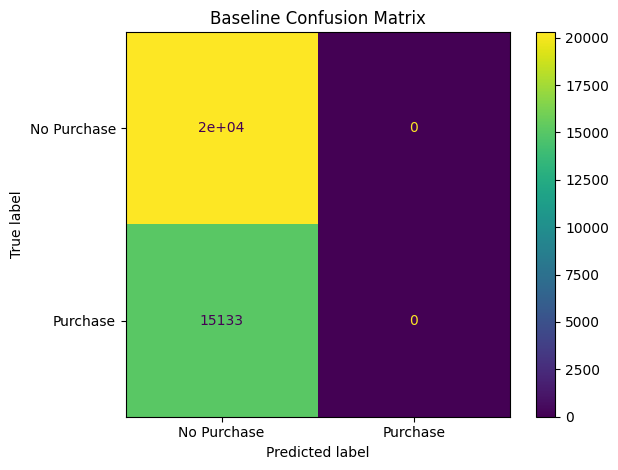

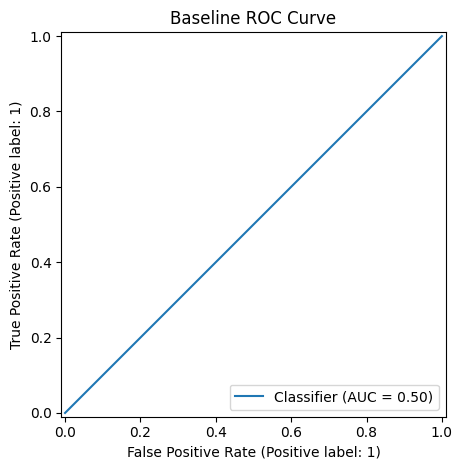


Model: Logistic Regression
Accuracy: 0.6573
Precision: 0.5883
Recall: 0.6589
F1 Score: 0.6216
ROC AUC: 0.7189


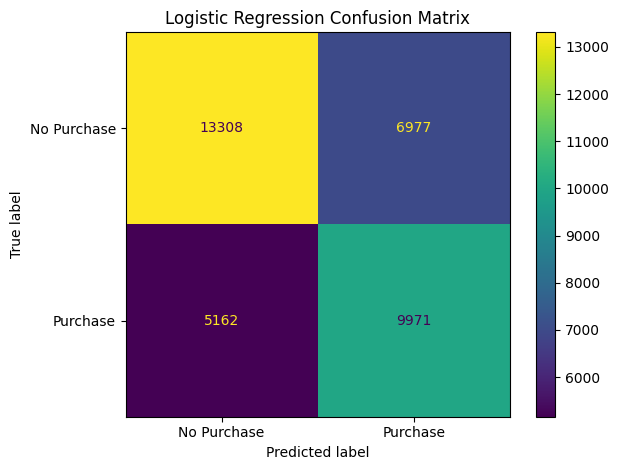

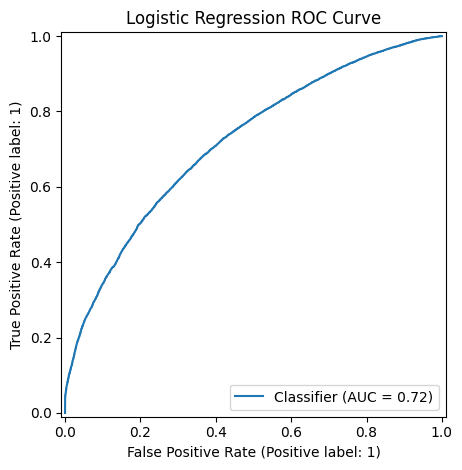


Model: Decision Tree
Accuracy: 0.6933
Precision: 0.6874
Recall: 0.5175
F1 Score: 0.5905
ROC AUC: 0.7443


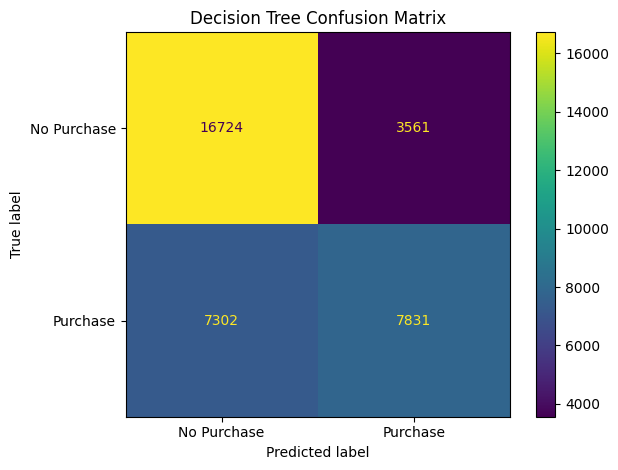

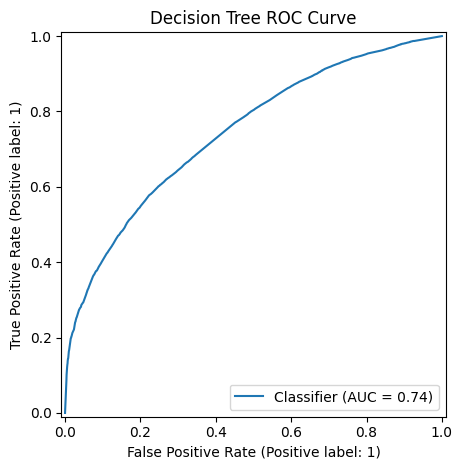


Model: Naive Bayes
Accuracy: 0.6387
Precision: 0.5728
Recall: 0.6067
F1 Score: 0.5893
ROC AUC: 0.6835


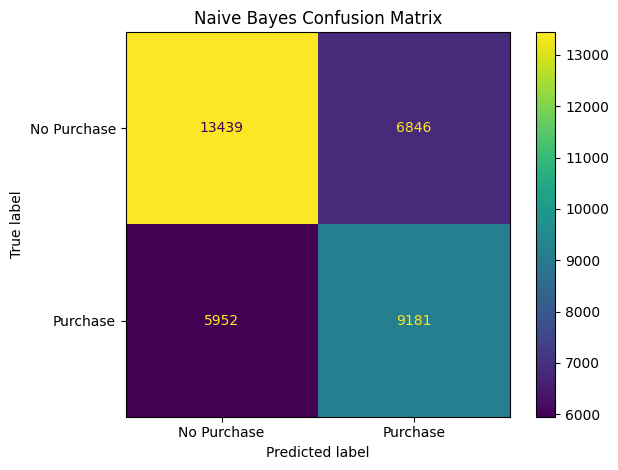

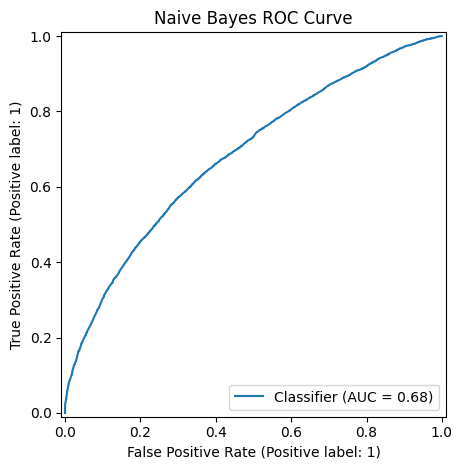

In [20]:

#Final Model Evaluation

results = []

for name, model in best_models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_valid)
    probabilities = model.predict_proba(X_valid)[:, 1]

    accuracy = accuracy_score(y_valid, predictions)
    precision = precision_score(
        y_valid, predictions, zero_division=0
    )
    recall = recall_score(
        y_valid, predictions, zero_division=0
    )
    f1 = f1_score(
        y_valid, predictions, zero_division=0
    )
    auc = roc_auc_score(y_valid, probabilities)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC_AUC": auc
    })

    print("\nModel:", name)
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))
    print("ROC AUC:", round(auc, 4))

    # Confusion Matrix
    cm = confusion_matrix(y_valid, predictions)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Purchase", "Purchase"]
    ).plot()

    plt.title(name + " Confusion Matrix")
    plt.tight_layout()
    plt.savefig(
        name.replace(" ", "_") + "_confusion.png"
    )
    plt.show()

    # ROC Curve
    RocCurveDisplay.from_predictions(
        y_valid, probabilities
    )

    plt.title(name + " ROC Curve")
    plt.tight_layout()
    plt.savefig(
        name.replace(" ", "_") + "_roc.png"
    )
    plt.show()


Compare Models

Model Comparison:
              Model  Accuracy  Precision   Recall       F1  ROC_AUC
Logistic Regression  0.657265   0.588329 0.658891 0.621614 0.718930
      Decision Tree  0.693292   0.687412 0.517478 0.590462 0.744283
        Naive Bayes  0.638658   0.572846 0.606687 0.589281 0.683530
           Baseline  0.572731   0.000000 0.000000 0.000000 0.500000


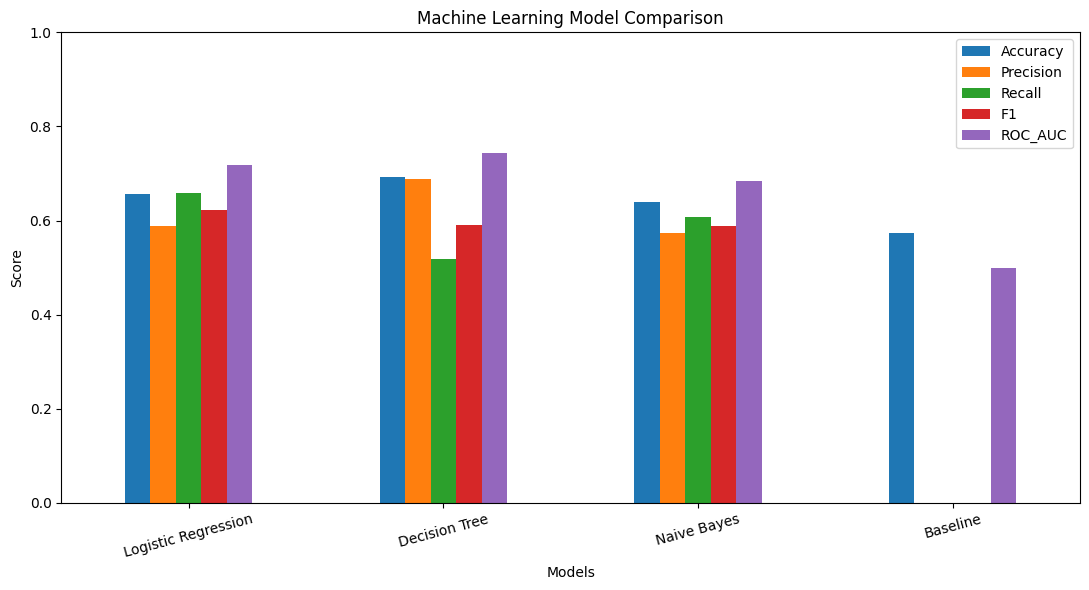

In [21]:

# Compare Models

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "F1", ascending=False
)

print("Model Comparison:")
print(results_df.to_string(index=False))

results_df.to_csv(
    "model_comparison.csv", index=False
)

results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]
].plot(kind="bar", figsize=(11, 6))

plt.title("Machine Learning Model Comparison")
plt.xlabel("Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend()
plt.tight_layout()
plt.savefig("model_comparison.png")
plt.show()


Select the Best Model

In [22]:

# Select the Best Model

# Select the model using training cross-validation F1

candidate_results = cv_df[
    cv_df["Model"] != "Baseline"
]

best_name = candidate_results.sort_values(
    "F1", ascending=False
).iloc[0]["Model"]

print("Selected Model:", best_name)

best_model = best_models[best_name]

# Train the final model using all labelled data
best_model.fit(X, y)

# Save the model
joblib.dump(
    best_model,
    "customer_purchase_model.pkl"
)

# Save feature names
joblib.dump(
    X.columns.tolist(),
    "model_columns.pkl"
)



Selected Model: Logistic Regression


['model_columns.pkl']

Predict the Testing Dataset

In [23]:

#Predict the Testing Dataset

test_predictions = best_model.predict(X_test)

test_probabilities = best_model.predict_proba(
    X_test
)[:, 1]

prediction_output = pd.DataFrame({
    "ID": test_clean["ID"],
    "Predicted_Result": test_predictions,
    "Purchase_Probability": test_probabilities
})

print("First 10 Predictions:")
print(prediction_output.head(10))

print("\nPrediction Summary:")
print(prediction_output["Predicted_Result"].value_counts())

prediction_output.to_csv(
    "customer_purchase_predictions.csv",
    index=False
)



First 10 Predictions:
       ID  Predicted_Result  Purchase_Probability
0  177087                 1              0.624141
1  177088                 0              0.338942
2  177089                 0              0.248058
3  177090                 0              0.335267
4  177091                 0              0.283006
5  177092                 0              0.277151
6  177093                 1              0.540087
7  177094                 1              0.557285
8  177095                 1              0.695763
9  177096                 1              0.574700

Prediction Summary:
Predicted_Result
0    30429
1    13843
Name: count, dtype: int64


Final Project Summary

In [24]:

# Final Project Summary

print("CUSTOMER PURCHASE PREDICTION PROJECT")
print("-----------------------------------")

print("Training Records:", len(train))
print("Testing Records:", len(test))
print("Predictor Columns:", len(X.columns))

print("\nSelected Model:", best_name)

print("\nModel Performance:")
print(results_df.to_string(index=False))

print("\nProject completed successfully.")


CUSTOMER PURCHASE PREDICTION PROJECT
-----------------------------------
Training Records: 177086
Testing Records: 44272
Predictor Columns: 18

Selected Model: Logistic Regression

Model Performance:
              Model  Accuracy  Precision   Recall       F1  ROC_AUC
Logistic Regression  0.657265   0.588329 0.658891 0.621614 0.718930
      Decision Tree  0.693292   0.687412 0.517478 0.590462 0.744283
        Naive Bayes  0.638658   0.572846 0.606687 0.589281 0.683530
           Baseline  0.572731   0.000000 0.000000 0.000000 0.500000

Project completed successfully.
